IMPORTING THE LIBRARIES FIRST

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

### load dataset

In [2]:
df=pd.read_csv("../dataset/train.csv")

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.shape

(614, 13)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


    checking null values

In [7]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

    DATA CLEANING

In [8]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [9]:
df.duplicated().sum()

np.int64(0)

    HANDLING MISSING VALUES

In [10]:
cat_cols=['Gender','Married','Dependents','Self_Employed']

for col in cat_cols:
    df[col]=df[col].fillna(df[col].mode()[0]) ## mode() returns series so 0 index is used

In [11]:
df.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

    HANDLING NULL VALUES FOR NUMERICAL COLUMNS

In [12]:
num_cols=['LoanAmount','Loan_Amount_Term','Credit_History']

for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [13]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

    DROPPING UNNECESSARY COLUMN

In [14]:
df.drop("Loan_ID",axis=1,inplace=True)

In [15]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    object 
 1   Married            614 non-null    object 
 2   Dependents         614 non-null    object 
 3   Education          614 non-null    object 
 4   Self_Employed      614 non-null    object 
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    object 
 11  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 57.7+ KB


In [20]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col]=encoder.fit_transform(df[col])

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    int64  
 1   Married            614 non-null    int64  
 2   Dependents         614 non-null    int64  
 3   Education          614 non-null    int64  
 4   Self_Employed      614 non-null    int64  
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    int64  
 11  Loan_Status        614 non-null    int64  
dtypes: float64(4), int64(8)
memory usage: 57.7 KB


In [22]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


    TRAIN_TEST SPLIT

In [23]:
x=df.drop("Loan_Status",axis=1)
y=df["Loan_Status"]

In [24]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [25]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((491, 11), (123, 11), (491,), (123,))

    FEATURE SCALING

In [26]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

    USING LOGISTIC REGRESSION

In [27]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [28]:
model.coef_

array([[-0.06781084,  0.31311595,  0.11793007, -0.15936104,  0.04992137,
        -0.0270309 , -0.15219934, -0.17650381,  0.04501436,  1.31088131,
         0.07732128]])

In [29]:
model.intercept_

array([0.88413473])

    PREDICTION

In [30]:
y_pred=model.predict(x_test)

    ACCURACY

In [31]:
from sklearn.metrics import accuracy_score

accuracy=accuracy_score(y_test,y_pred)

print("the accuracy of our model is:",accuracy)

the accuracy of our model is: 0.7886178861788617


In [32]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print(cm)

print(classification_report(y_test, y_pred))

[[18 25]
 [ 1 79]]
              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



    ROC CURVE,AUC

In [33]:
from sklearn.metrics import roc_curve,roc_auc_score

roc curve doesnt need prediction between 0 and 1.it needs probability

In [34]:
y_prob=model.predict_proba(x_test)[:,1] ## we want prob of class 1 only which is approval
## predict_proba returns thr prob oof every class

fpr,tpr,thresholds=roc_curve(y_test,y_prob)

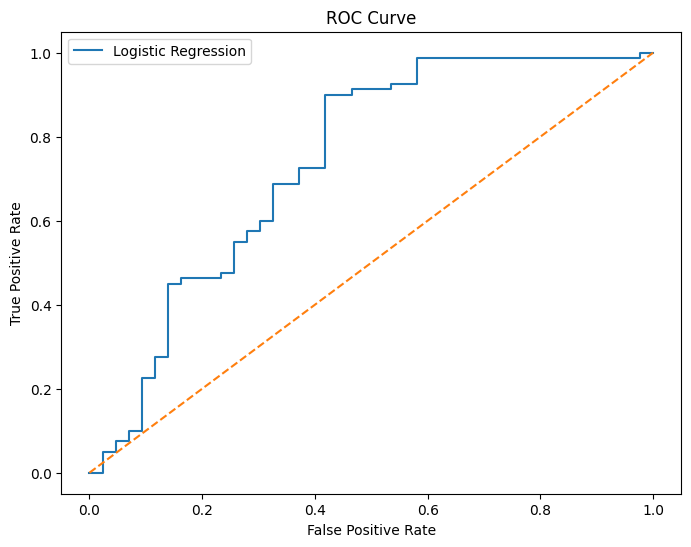

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label="Logistic Regression")

plt.plot([0,1], [0,1], '--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [36]:
y_prob=model.predict_proba(x_test)[:,1] ## we want prob of class 1 only
auc=roc_auc_score(y_test,y_prob)
print("AUC:",auc)

AUC: 0.7386627906976744


    cross validation

In [37]:
from sklearn.model_selection import cross_val_score

cv_score=cross_val_score(
    model,x_train,y_train,cv=5,scoring='accuracy'
)
print("Fold accuracies:",cv_score)
print("Average accuracy:",cv_score.mean())

Fold accuracies: [0.84848485 0.80612245 0.81632653 0.79591837 0.80612245]
Average accuracy: 0.8145949288806431


## hyperparameter tuning

    GRID SEARCH CV

In [38]:
import warnings
warnings.filterwarnings("ignore")

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

grid = GridSearchCV(
    estimator=LogisticRegression(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(x_test)


Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV Score: 0.8145949288806431


In [40]:
from sklearn.metrics import accuracy_score

print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.7886178861788617


    DECISION TREE ALGORITHM

In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [42]:
dt_model = DecisionTreeClassifier(random_state=42)

In [43]:
dt_model.fit(x_train, y_train)
y_pred_dt=dt_model.predict(x_test)
y_pred_dt

array([1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0])

In [44]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(confusion_matrix(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.6910569105691057
[[23 20]
 [18 62]]
              precision    recall  f1-score   support

           0       0.56      0.53      0.55        43
           1       0.76      0.78      0.77        80

    accuracy                           0.69       123
   macro avg       0.66      0.65      0.66       123
weighted avg       0.69      0.69      0.69       123



    CROSS VAL SCORE

In [45]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(dt_model, x_train, y_train, cv=5)

print("CV Scores:", cv_scores)
print("Average CV:", cv_scores.mean())

CV Scores: [0.71717172 0.69387755 0.71428571 0.74489796 0.76530612]
Average CV: 0.7271078128220985


    HYPERPARAMETER TUNING OF DECISION TREE

In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)


In [47]:
grid_dt.fit(x_train, y_train)

print("Best Parameters:", grid_dt.best_params_)
print("Best CV Score:", grid_dt.best_score_)

best_dt = grid_dt.best_estimator_

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Score: 0.8064522778808494


In [48]:

y_pred_dt = best_dt.predict(x_test)

In [49]:

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))
print(confusion_matrix(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Test Accuracy: 0.7886178861788617
[[18 25]
 [ 1 79]]
              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



    RANDOM FOREST

importing libraries

In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model

In [51]:
rf_model = RandomForestClassifier(random_state=42,
n_estimators = 100,criterion = 'gini',max_depth = None,bootstrap = True)
##default values

training and prediction

In [52]:
rf_model.fit(x_train, y_train) ## training
y_pred_rf = rf_model.predict(x_test) ## prediction

In [53]:
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

[[18 25]
 [ 6 74]]
              precision    recall  f1-score   support

           0       0.75      0.42      0.54        43
           1       0.75      0.93      0.83        80

    accuracy                           0.75       123
   macro avg       0.75      0.67      0.68       123
weighted avg       0.75      0.75      0.73       123



    CROSS VALIDATION

In [54]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(rf_model,x_train,y_train,cv=5)

print("CV Scores:", cv_scores)
print("Average CV:", cv_scores.mean())

CV Scores: [0.86868687 0.78571429 0.74489796 0.79591837 0.82653061]
Average CV: 0.804349618635333


    TUNING

In [55]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [56]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

GRID SEARCH CV

In [57]:
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1 ## use all cores of cpu to make execution faster
)

    TRAIN

In [58]:
grid_rf.fit(x_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,50


In [59]:
print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", grid_rf.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 50}
Best CV Score: 0.8145743145743145


    Best Model

In [60]:
best_rf = grid_rf.best_estimator_
best_rf

,n_estimators,50
,criterion,'gini'
,max_depth,5
,min_samples_split,10
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### prediction using bes_rf

In [61]:
y_pred_rf = best_rf.predict(x_test)

In [62]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Test Accuracy: 0.7886178861788617
[[18 25]
 [ 1 79]]
              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



    EXTREME BOOST ALGORITHM

In [63]:
!pip install xgboost

In [64]:
from xgboost import XGBClassifier

In [65]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(x_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


    prediction

In [66]:
y_pred_xgb = xgb_model.predict(x_test)

In [67]:
from sklearn.metrics import accuracy_score

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.7642276422764228


In [68]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

Confusion Matrix:
[[19 24]
 [ 5 75]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.44      0.57        43
           1       0.76      0.94      0.84        80

    accuracy                           0.76       123
   macro avg       0.77      0.69      0.70       123
weighted avg       0.77      0.76      0.74       123



    HYPERPARAMETER TUNING

In [69]:
from sklearn.model_selection import cross_val_score

xgb_cv_scores = cross_val_score(
    xgb_model,
    x_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("XGBoost CV Scores:", xgb_cv_scores)
print("Average CV Score:", xgb_cv_scores.mean())

XGBoost CV Scores: [0.85858586 0.78571429 0.7755102  0.7755102  0.79591837]
Average CV Score: 0.7982477839620696


    GRID SEARCH CV

In [70]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search_xgb.fit(x_train, y_train)

print("Best Parameters:", grid_search_xgb.best_params_)
print("Best CV Score:", grid_search_xgb.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
Best CV Score: 0.8145949288806431


    Best tuned XGBoost model


In [71]:
best_xgb_model = grid_search_xgb.best_estimator_

# Prediction on test data
y_pred_xgb_tuned = best_xgb_model.predict(x_test)

# Test accuracy
from sklearn.metrics import accuracy_score

xgb_tuned_accuracy = accuracy_score(
    y_test,
    y_pred_xgb_tuned
)

print(
    "Tuned XGBoost Test Accuracy:",
    xgb_tuned_accuracy
)

Tuned XGBoost Test Accuracy: 0.7886178861788617


In [72]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_xgb_tuned
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb_tuned
    )
)

Confusion Matrix:
[[18 25]
 [ 1 79]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



In [73]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_tuned))

Confusion Matrix:
[[18 25]
 [ 1 79]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



    XAI

In [74]:
!pip install shap

In [75]:
import shap

# Create SHAP explainer for XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer(x_test)

print("SHAP values generated successfully!")

SHAP values generated successfully!


    SUMMARY PLOT GRAPH

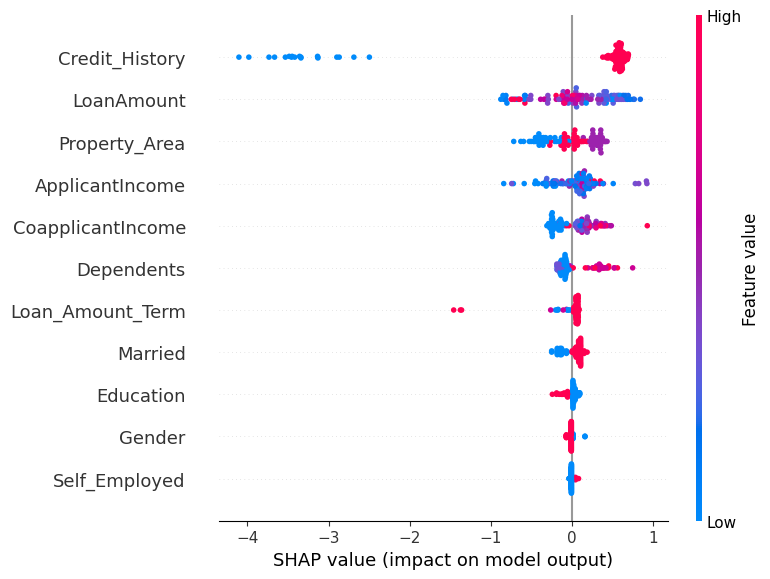

In [76]:
feature_names = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "Property_Area"
]

shap.summary_plot(
    shap_values,
    x_test,
    feature_names=feature_names
)

## XAI using SHAP

SHAP (SHapley Additive exPlanations) was used to explain the predictions made by the XGBoost model. The SHAP summary plot shows the global importance and impact of each feature on loan approval predictions.

Credit_History was found to be the most influential feature, followed by LoanAmount and Property_Area. Positive SHAP values increase the probability of loan approval, while negative SHAP values push the prediction toward loan rejection.

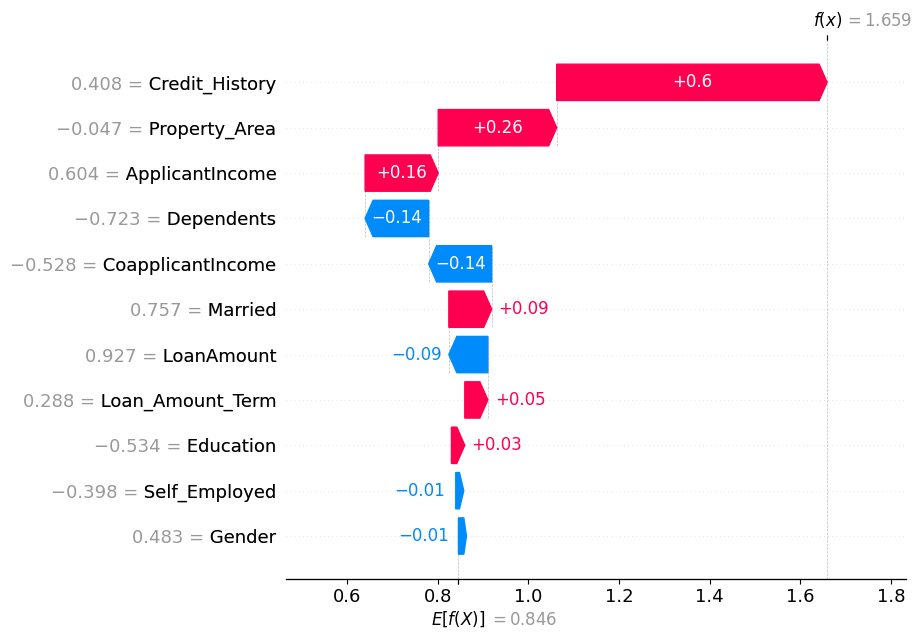

In [84]:
# import pandas as pd

# # Convert x_test into a DataFrame with feature names
# x_test_df = pd.DataFrame(
#     x_test,
#     columns=feature_names
# )

# # Generate SHAP values again using the DataFrame
# shap_values_df = explainer(x_test_df)

# # Individual applicant explanation
# shap.plots.waterfall(
#     shap_values_df[0]
# )

import pandas as pd
import shap
import matplotlib.pyplot as plt

# Convert x_test to DataFrame
x_test_df = pd.DataFrame(x_test, columns=feature_names)

# Explain only one applicant
applicant = x_test_df.iloc[[0]]

# Calculate SHAP values only for this applicant
shap_values = explainer(applicant)

# Plot
shap.plots.waterfall(shap_values[0], max_display=20)
plt.show()


In [85]:
actual_value = y_test.iloc[0] #first position
predicted_value = y_pred_xgb[0]

print("Actual Loan Status:", actual_value)
print("Predicted Loan Status:", predicted_value)

if predicted_value == 1:
    print("Prediction: Loan Approved")
else:
    print("Prediction: Loan Rejected")

Actual Loan Status: 1
Predicted Loan Status: 1
Prediction: Loan Approved


## Conclusion

XGBoost achieved an accuracy of 76.42% on the test dataset. However, Logistic Regression achieved a higher accuracy of 78.86%, so Logistic Regression was retained as the final deployed model.

SHAP Explainable AI was integrated with the XGBoost model to provide both global and local explanations. The SHAP summary plot identified the most influential features affecting loan approval predictions, while the waterfall plot explained the contribution of each feature for an individual applicant.

    SAVING THE MODEL

In [86]:
import joblib

joblib.dump(xgb_model, "xgb_model.pkl")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [87]:
import joblib
## saving the trained logistic regression model
joblib.dump(model, "loan_model.pkl")
## saving the standard scaler
joblib.dump(scaler, "scaler.pkl")

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!
